# Tomorrow's Connecticut demand: the full forecast

**Dr. Dave · University of Connecticut** · demo, October 2026

Everything from the earlier demos, plus memory:
- **Weather windows:** temperature 1, 3, 6 and 24 hours earlier, and the last 24 hours' average, high and low.
  Buildings warm up and cool down slowly.
- **Load lags:** Connecticut's load 2 days earlier and 7 days earlier, at the same hour.
- **Weather uncertainty:** NOAA's GEFS ensemble (30 runs), via [hefty](https://github.com/williamhobbs/hefty) (Will Hobbs, Southern Company).
- **Model uncertainty:** a quantile random forest, which gives percentiles instead of a single number.
- **A benchmark:** ISO New England's own Connecticut forecast.

Data: a ready-made history file (Connecticut load + Bradley weather, Jan 2023 to Oct 2026, built from ISO-NE and the Iowa State
Mesonet). The last 10 days of both, plus all forecasts, are downloaded live. Runtime -> Run all, about 8 minutes.

## Setup
`hefty` needs Python 3.12 or newer (Colab has it). If Colab asks to restart after the install, click **Restart**, then **Run all**.

In [1]:
try:
    import hefty
    import quantile_forest
    print('hefty and quantile-forest already installed')
except ImportError:
    !pip install -q hefty quantile-forest

hefty and quantile-forest already installed


In [2]:
import io
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import requests
import pvlib
from pandas.tseries.holiday import USFederalHolidayCalendar
from hefty.solar import get_solar_forecast, get_solar_forecast_ensemble
from hefty.utilities import adjust_forecast_datetimes
from quantile_forest import RandomForestQuantileRegressor

warnings.filterwarnings('ignore')
pd.set_option('display.width', 180)

In [3]:
SETTINGS = {
    'latitude': 41.9389,                 # Bradley Airport (BDL)
    'longitude': -72.6832,
    'history_url': 'https://raw.githubusercontent.com/drdave-teaching/energy-forecasting/hefty-test/explorations/data/ct_load_weather_hourly_2023_2026.csv',
    'native_scale': 1.0113,              # ISO's estimated zone load runs 1.1% above the history file's load (checked on 6,579 hours)
    'backtest_days': 90,
    'quantiles': [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95],
    'seed': 5509,
}
SITE = pvlib.location.Location(SETTINGS['latitude'], SETTINGS['longitude'])
NOW = pd.Timestamp.now(tz='UTC').floor('h')
TOMORROW = pd.Timestamp.now(tz='America/New_York').normalize() + pd.Timedelta(days=1)
HOURS = pd.date_range(TOMORROW.tz_convert('UTC'), periods=24, freq='h')
print('now', NOW, '| forecasting', TOMORROW.date())

now 2026-10-16 20:00:00+00:00 | forecasting 2026-10-17


## Step 1: history, topped up to today
The history file ends when it was built; the last 10 days come straight from the sources: ISO-NE's five-minute estimated
Connecticut zone load (public) and Bradley's airport reports (Iowa State Mesonet).

In [4]:
history = pd.read_csv(SETTINGS['history_url'], index_col='hour_utc', parse_dates=True)
print('history file:', history.shape, history.index.min(), '->', history.index.max())

UA = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/141.0 Safari/537.36'}
iso = requests.Session()
iso.headers.update(UA)
page = iso.get('https://www.iso-ne.com/isoexpress/web/reports/load-and-demand/-/tree/estimated-zonal-load', timeout=60)
start = (NOW - pd.Timedelta(days=10)).tz_convert('America/New_York')
end = NOW.tz_convert('America/New_York')
r = iso.get('https://www.iso-ne.com/transform/csv/fiveminuteestimatedzonalload?start=' + start.strftime('%Y%m%d') + '&end=' + end.strftime('%Y%m%d'),
            headers={'Referer': page.url}, timeout=300)
rows = []
for line in r.text.splitlines():
    p = line.replace('"', '').split(',')
    if len(p) >= 6 and p[0] == 'D' and p[2] == '4004':          # 4004 = Connecticut load zone
        rows.append({'t': p[1], 'ct_load_mw': float(p[4])})
zone = pd.DataFrame(rows)
zone['t'] = pd.to_datetime(zone['t'], format='%m/%d/%Y %H:%M:%S').dt.tz_localize('America/New_York', ambiguous='NaT', nonexistent='NaT').dt.tz_convert('UTC')
recent_load = zone.dropna().set_index('t')['ct_load_mw'].resample('h').mean() / SETTINGS['native_scale']
print('recent Connecticut load:', recent_load.shape, recent_load.index.min(), '->', recent_load.index.max())

history file: (33230, 3) 2023-01-01 05:00:00+00:00 -> 2026-10-16 18:00:00+00:00


recent Connecticut load: (256,) 2026-10-06 04:00:00+00:00 -> 2026-10-16 19:00:00+00:00


In [5]:
s, e = NOW - pd.Timedelta(days=10), NOW + pd.Timedelta(days=1)
url = ('https://mesonet.agron.iastate.edu/cgi-bin/request/asos.py?station=BDL&data=tmpf&data=skyc1&data=skyc2&data=skyc3&data=skyc4'
       f'&year1={s.year}&month1={s.month}&day1={s.day}&year2={e.year}&month2={e.month}&day2={e.day}&tz=Etc%2FUTC&format=onlycomma&report_type=3&report_type=4')
raw = pd.read_csv(io.StringIO(requests.get(url, timeout=120).text), na_values=['M'], keep_default_na=False)
raw['valid'] = pd.to_datetime(raw['valid'], utc=True)
raw['hour_utc'] = raw['valid'].dt.round('h')                       # 10:51 -> 11:00, as in Lab 5
raw['minutes_off'] = (raw['valid'] - raw['hour_utc']).abs().dt.total_seconds() / 60
raw['is_routine'] = raw['valid'].dt.minute == 51
raw = raw.sort_values(['hour_utc', 'is_routine', 'minutes_off'], ascending=[True, False, True]).drop_duplicates('hour_utc')
SKY = {'CLR': 0, 'FEW': 19, 'SCT': 44, 'BKN': 75, 'OVC': 100, 'VV': 100}
layers = pd.DataFrame(index=raw.index)
for c in ['skyc1', 'skyc2', 'skyc3', 'skyc4']:
    layers[c] = raw[c].astype(str).str.strip().map(SKY)
recent_wx = pd.DataFrame({'temp_f': pd.to_numeric(raw['tmpf'], errors='coerce').values,
                          'cloud_cover_pct': layers.max(axis=1).values}, index=pd.DatetimeIndex(raw['hour_utc']))
recent_wx = recent_wx[recent_wx.index <= NOW].sort_index()
print('recent Bradley weather:', recent_wx.shape, recent_wx.index.min(), '->', recent_wx.index.max())

recent Bradley weather: (260, 2) 2026-10-06 01:00:00+00:00 -> 2026-10-16 20:00:00+00:00


In [6]:
recent = pd.DataFrame({'load_mw': recent_load}).join(recent_wx, how='outer')
data = pd.concat([history, recent[recent.index > history.index.max()]])
data = data[~data.index.duplicated(keep='first')].sort_index()
data = data.reindex(pd.date_range(data.index.min(), NOW, freq='h'))
data[['temp_f', 'cloud_cover_pct']] = data[['temp_f', 'cloud_cover_pct']].interpolate(limit=6, limit_direction='both')
data.index.name = 'hour_utc'
print('history + last 10 days:', data.shape, data.index.min(), '->', data.index.max())
data.tail(3)

history + last 10 days: (33232, 3) 2023-01-01 05:00:00+00:00 -> 2026-10-16 20:00:00+00:00


,load_mw,temp_f,cloud_cover_pct
hour_utc,,,
2026-10-16 18:00:00+00:00,3140.000000,66.0,100.0
2026-10-16 19:00:00+00:00,3092.709384,67.0,100.0
2026-10-16 20:00:00+00:00,NaN,68.0,75.0


## Step 2: features
One function builds every column, so the training table and tomorrow's table are made exactly the same way.

| group | columns |
|---|---|
| clock | hour, day of week, month, weekend, holiday |
| weather now | temperature, sunlight (clear-sky sun dimmed by cloud cover), heating and cooling degrees (65 °F base) |
| weather windows | temperature 1, 3, 6, 24 h earlier; 24-h average, high, low; sunlight 1 h earlier |
| load lags | load 48 h and 168 h earlier (both known when we forecast; 24 h earlier is not, for tomorrow's evening) |

In [7]:
HOLIDAYS = USFederalHolidayCalendar().holidays(start='2022-01-01', end='2027-12-31')


def add_features(df):
    local = df.index.tz_convert('America/New_York')
    df['hour_local'] = local.hour
    df['day_of_week'] = local.dayofweek
    df['month'] = local.month
    df['is_weekend'] = (local.dayofweek >= 5).astype(int)
    df['is_holiday'] = pd.Index(local.normalize().tz_localize(None)).isin(HOLIDAYS).astype(int)
    df['hdd'] = (65 - df['temp_f']).clip(lower=0)
    df['cdd'] = (df['temp_f'] - 65).clip(lower=0)
    for lag in [1, 3, 6, 24]:
        df['temp_lag_' + str(lag) + 'h'] = df['temp_f'].shift(lag)
    df['temp_mean_24h'] = df['temp_f'].rolling(24, min_periods=18).mean()
    df['temp_max_24h'] = df['temp_f'].rolling(24, min_periods=18).max()
    df['temp_min_24h'] = df['temp_f'].rolling(24, min_periods=18).min()
    df['sun_lag_1h'] = df['sun'].shift(1)
    df['load_lag_48h'] = df['load_mw'].shift(48)
    df['load_lag_168h'] = df['load_mw'].shift(168)
    return df


def sun_from_cloud(index, cloud_pct):
    clear = SITE.get_clearsky(index + pd.Timedelta(minutes=30), model='ineichen')['ghi'].values
    return clear * (1 - 0.75 * (np.asarray(cloud_pct, dtype=float) / 100) ** 3.4)


CLOCK = ['hour_local', 'day_of_week', 'month', 'is_weekend', 'is_holiday']
WEATHER_NOW = ['temp_f', 'sun', 'hdd', 'cdd']
WINDOWS = ['temp_lag_1h', 'temp_lag_3h', 'temp_lag_6h', 'temp_lag_24h', 'temp_mean_24h', 'temp_max_24h', 'temp_min_24h', 'sun_lag_1h']
LOAD_LAGS = ['load_lag_48h', 'load_lag_168h']
FEATURE_SETS = {
    'clock + weather now': CLOCK + WEATHER_NOW,
    '+ weather windows': CLOCK + WEATHER_NOW + WINDOWS,
    '+ windows + load lags': CLOCK + WEATHER_NOW + WINDOWS + LOAD_LAGS,
}

data['sun'] = sun_from_cloud(data.index, data['cloud_cover_pct'])
table = add_features(data.copy())
print('feature table:', table.shape)
table[FEATURE_SETS['+ windows + load lags'] + ['load_mw']].dropna().tail(3)

feature table: (33232, 21)


,hour_local,day_of_week,month,is_weekend,is_holiday,temp_f,sun,hdd,cdd,temp_lag_1h,temp_lag_3h,temp_lag_6h,temp_lag_24h,temp_mean_24h,temp_max_24h,temp_min_24h,sun_lag_1h,load_lag_48h,load_lag_168h,load_mw
hour_utc,,,,,,,,,,,,,,,,,,,,
2026-10-16 17:00:00+00:00,13,4,10,0,0,65.0,149.847205,0.0,0.0,63.0,56.0,54.0,61.0,54.708333,65.0,46.0,155.745362,3152.0,2380.4,3149.300000
2026-10-16 18:00:00+00:00,14,4,10,0,0,66.0,129.675545,0.0,1.0,65.0,60.0,54.0,61.0,54.916667,66.0,46.0,149.847205,2941.2,2451.8,3140.000000
2026-10-16 19:00:00+00:00,15,4,10,0,0,67.0,96.867373,0.0,2.0,66.0,63.0,55.0,64.0,55.041667,67.0,46.0,129.675545,3051.0,2579.0,3092.709384


## Step 3: does each step help? A 90-day backtest
Train on everything before the last 90 days, test on those 90 days (with the weather that actually happened). Score the median
(MAE) and the 80% band: an honest band contains the truth about 80% of the time.

In [8]:
last = table['load_mw'].last_valid_index()
cut = last - pd.Timedelta(days=SETTINGS['backtest_days'])
results = []
for name in FEATURE_SETS:
    cols = FEATURE_SETS[name]
    d = table.dropna(subset=cols + ['load_mw'])
    train = d[d.index <= cut]
    test = d[d.index > cut]
    m = RandomForestQuantileRegressor(n_estimators=200, min_samples_leaf=10, max_features=0.6, random_state=SETTINGS['seed'], n_jobs=-1)
    m.fit(train[cols], train['load_mw'])
    q = m.predict(test[cols], quantiles=[0.1, 0.5, 0.9])
    y = test['load_mw'].values
    results.append({'features': name, 'columns': len(cols), 'train rows': len(train), 'test rows': len(test),
                    'MAE (MW)': np.mean(np.abs(y - q[:, 1])), 'MAPE %': 100 * np.mean(np.abs(y - q[:, 1]) / y),
                    '80% band coverage %': 100 * np.mean((y >= q[:, 0]) & (y <= q[:, 2])),
                    'band width (MW)': np.mean(q[:, 2] - q[:, 0])})
pd.DataFrame(results).round(1)

,features,columns,train rows,test rows,MAE (MW),MAPE %,80% band coverage %,band width (MW)
0,clock + weather now,9,31057,2153,183.7,5.6,78.6,585.8
1,+ weather windows,17,31033,2153,176.2,5.3,71.5,478.4
2,+ windows + load lags,19,30861,2139,159.6,4.8,82.0,525.6


## Step 4: train the final model on everything

In [9]:
FINAL = FEATURE_SETS['+ windows + load lags']
d = table.dropna(subset=FINAL + ['load_mw'])
model = RandomForestQuantileRegressor(n_estimators=300, min_samples_leaf=10, max_features=0.6, random_state=SETTINGS['seed'], n_jobs=-1)
model.fit(d[FINAL], d['load_mw'])
print('final model trained on', d.shape, 'rows x columns, through', d.index.max())

final model trained on (33000, 21) rows x columns, through 2026-10-16 19:00:00+00:00


## Step 5: tomorrow's weather - 30 GEFS runs and HRRR
Each forecast is stitched onto the observed weather up to now, so the 24-hour windows for tomorrow's early hours use real
observations and the later ones use the forecast - exactly what would be known when the forecast is made.

In [10]:
need_from = NOW + pd.Timedelta(hours=1)
run_needed = int((HOURS[-1] - need_from) / pd.Timedelta(hours=1)) + 1
t0 = time.time()
init_g, rl_g, ls_g = adjust_forecast_datetimes(NOW.tz_localize(None), run_needed, 1, model='gefs')
ens = get_solar_forecast_ensemble(SETTINGS['latitude'], SETTINGS['longitude'], init_g, rl_g, ls_g, model='gefs', get_ens_temp=True)
ens.index = ens.index.floor('h')
print('GEFS run', init_g, '| table', ens.shape, '| members', ens['member'].nunique(), '|', round(time.time() - t0), 's')
init_h, rl_h, ls_h = adjust_forecast_datetimes(NOW.tz_localize(None), run_needed, 1, model='hrrr')
hrrr = get_solar_forecast(SETTINGS['latitude'], SETTINGS['longitude'], init_h, run_length=rl_h, lead_time_to_start=ls_h, model='hrrr')
hrrr.index = hrrr.index.floor('h')
hrrr = hrrr[~hrrr.index.duplicated()]
print('HRRR run', init_h, '| table', hrrr.shape)

GEFS run 2026-10-16 12:00:00+00:00 | table (990, 11) | members 30 | 139 s
✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2026-Oct-16 18:00 UTC F03 ┊ GRIB2 @ aws ┊ IDX @ local


Note: Returning a list of [3] xarray.Datasets because cfgrib opened with multiple hypercubes.


✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2026-Oct-16 18:00 UTC F04 ┊ GRIB2 @ aws ┊ IDX @ local


Note: Returning a list of [3] xarray.Datasets because cfgrib opened with multiple hypercubes.


✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2026-Oct-16 18:00 UTC F05 ┊ GRIB2 @ aws ┊ IDX @ local


...

✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2026-Oct-16 18:00 UTC F33 ┊ GRIB2 @ aws ┊ IDX @ local


Note: Returning a list of [3] xarray.Datasets because cfgrib opened with multiple hypercubes.


✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2026-Oct-16 18:00 UTC F34 ┊ GRIB2 @ aws ┊ IDX @ local


Note: Returning a list of [3] xarray.Datasets because cfgrib opened with multiple hypercubes.


HRRR run 2026-10-16 18:00:00+00:00 | table (31, 12)


In [11]:
def tomorrow_table(fc_temp_f, fc_sun):
    past = data.loc[data.index >= NOW - pd.Timedelta(days=9), ['load_mw', 'temp_f', 'sun']]
    future_idx = pd.date_range(need_from, HOURS[-1], freq='h')
    future = pd.DataFrame(index=future_idx)
    future['load_mw'] = np.nan
    future['temp_f'] = fc_temp_f.reindex(future_idx).values
    future['sun'] = fc_sun.reindex(future_idx).values
    both = pd.concat([past, future])
    both['temp_f'] = both['temp_f'].interpolate(limit_direction='both')
    both['sun'] = both['sun'].fillna(0)
    return add_features(both).loc[HOURS]


QS = SETTINGS['quantiles']
pooled = []
member_medians = []
member_temps = []
for m in sorted(ens['member'].unique()):
    e = ens[ens['member'] == m]
    e = e[~e.index.duplicated()]
    X = tomorrow_table(e['temp_air'] * 9 / 5 + 32, e['ghi'])
    q = model.predict(X[FINAL], quantiles=QS)
    pooled.append(q)
    member_medians.append(q[:, QS.index(0.5)])
    member_temps.append(X['temp_f'].values)
pooled = np.concatenate(pooled, axis=1)
X_hrrr = tomorrow_table(hrrr['temp_air'] * 9 / 5 + 32, hrrr['ghi'])
print('tomorrow table per run:', X_hrrr[FINAL].shape, '| pooled predictions:', pooled.shape)
X_hrrr[FINAL].head(3)

tomorrow table per run: (24, 19) | pooled predictions: (24, 570)


,hour_local,day_of_week,month,is_weekend,is_holiday,temp_f,sun,hdd,cdd,temp_lag_1h,temp_lag_3h,temp_lag_6h,temp_lag_24h,temp_mean_24h,temp_max_24h,temp_min_24h,sun_lag_1h,load_lag_48h,load_lag_168h
2026-10-17 04:00:00+00:00,0,5,10,1,0,53.171944,0.0,11.828056,0.0,55.448971,62.499420,64.988235,49.0,58.328199,68.0,48.0,0.0,2359.3,2271.1
2026-10-17 05:00:00+00:00,1,5,10,1,0,52.021126,0.0,12.978874,0.0,53.171944,59.319839,64.370041,48.0,58.495746,68.0,48.0,0.0,2228.4,2170.2
2026-10-17 06:00:00+00:00,2,5,10,1,0,50.395260,0.0,14.604740,0.0,52.021126,55.448971,63.809124,48.0,58.595549,68.0,49.0,0.0,2143.8,2102.2


## Step 6: ISO New England's own forecast, for comparison
ISO-NE publishes a five-minute Connecticut forecast for the next 24 hours, so depending on when you run this it covers part of tomorrow.

In [12]:
page = iso.get('https://www.iso-ne.com/isoexpress/web/reports/load-and-demand/-/tree/zonal-load-forecast', timeout=60)
r = iso.get('https://www.iso-ne.com/transform/csv/fiveminutezonalloadforecast/current', headers={'Referer': page.url}, timeout=120)
rows = []
for line in r.text.splitlines():
    p = line.replace('"', '').split(',')
    if len(p) >= 5 and p[0] == 'D' and p[2] == '4004':
        rows.append({'t': p[1], 'mw': float(p[4])})
iso_fc = pd.DataFrame(rows)
iso_fc['t'] = pd.to_datetime(iso_fc['t'], format='%m/%d/%Y %H:%M:%S').dt.tz_localize('America/New_York', ambiguous='NaT', nonexistent='NaT')
iso_fc = iso_fc.dropna().set_index('t')['mw'].resample('h').mean() / SETTINGS['native_scale']
print('ISO forecast hours available for tomorrow:', int(iso_fc.reindex(HOURS.tz_convert('America/New_York')).notna().sum()))

ISO forecast hours available for tomorrow: 17


## Step 7: the forecast

In [13]:
local_hours = HOURS.tz_convert('America/New_York')
forecast = pd.DataFrame(index=local_hours)
forecast['p10'] = np.percentile(pooled, 10, axis=1)
forecast['median'] = np.percentile(pooled, 50, axis=1)
forecast['p90'] = np.percentile(pooled, 90, axis=1)
forecast['weather only p10'] = np.percentile(np.array(member_medians), 10, axis=0)
forecast['weather only p90'] = np.percentile(np.array(member_medians), 90, axis=0)
forecast['with HRRR'] = model.predict(X_hrrr[FINAL], quantiles=0.5)
forecast['ISO-NE forecast'] = iso_fc.reindex(local_hours).values
forecast['last week, same hour'] = X_hrrr['load_lag_168h'].values
forecast['GEFS median temp °F'] = np.median(np.array(member_temps), axis=0)
forecast.round(0)

,p10,median,p90,weather only p10,weather only p90,with HRRR,ISO-NE forecast,"last week, same hour",GEFS median temp °F
2026-10-17 00:00:00-04:00,2102.0,2190.0,2280.0,2187.0,2194.0,2194.0,2376.0,2271.0,52.0
2026-10-17 01:00:00-04:00,2021.0,2110.0,2207.0,2106.0,2116.0,2106.0,2232.0,2170.0,51.0
2026-10-17 02:00:00-04:00,1953.0,2030.0,2111.0,2030.0,2032.0,2032.0,2133.0,2102.0,49.0
2026-10-17 03:00:00-04:00,1952.0,2022.0,2097.0,2022.0,2025.0,2022.0,2084.0,2079.0,48.0
2026-10-17 04:00:00-04:00,1953.0,2027.0,2101.0,2026.0,2030.0,2026.0,2086.0,2085.0,47.0
2026-10-17 05:00:00-04:00,2017.0,2104.0,2216.0,2094.0,2113.0,2097.0,2159.0,2157.0,46.0
2026-10-17 06:00:00-04:00,2104.0,2210.0,2340.0,2205.0,2220.0,2206.0,2294.0,2310.0,45.0
2026-10-17 07:00:00-04:00,2201.0,2340.0,2489.0,2335.0,2354.0,2340.0,2467.0,2436.0,44.0
2026-10-17 08:00:00-04:00,2249.0,2428.0,2597.0,2426.0,2431.0,2426.0,2633.0,2440.0,44.0
2026-10-17 09:00:00-04:00,2311.0,2483.0,2742.0,2448.0,2506.0,2476.0,2735.0,2320.0,44.0


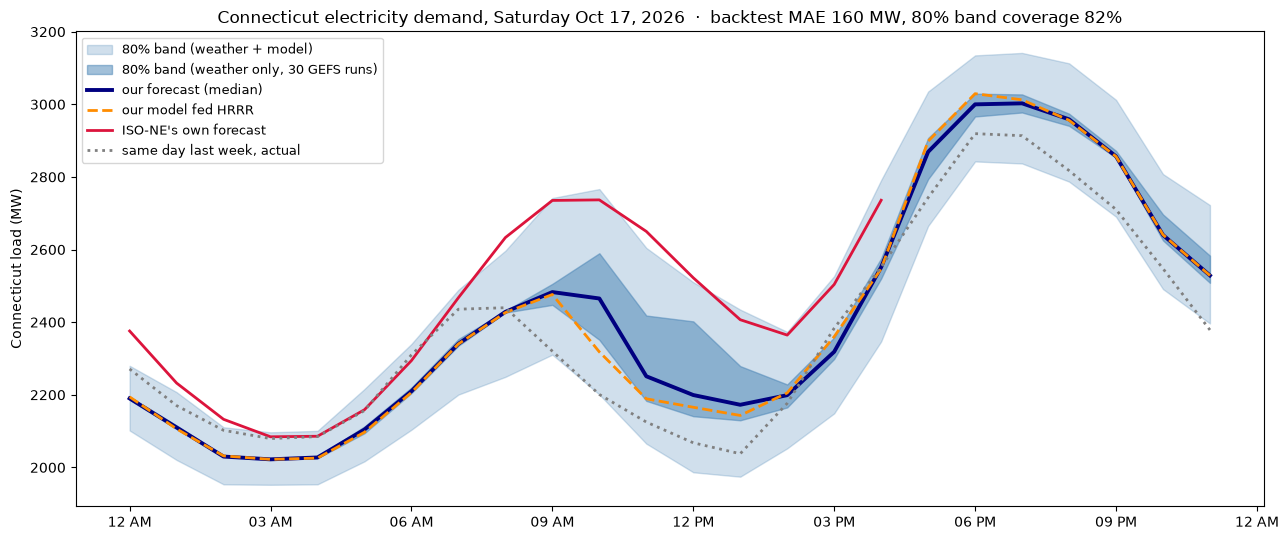

Peak at 07 PM: 3003 MW (80% band 2837-3142 MW)
Whole day: 57,959 MWh


In [14]:
backtest = pd.DataFrame(results).set_index('features')
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.fill_between(local_hours, forecast['p10'], forecast['p90'], color='steelblue', alpha=0.25, label='80% band (weather + model)')
ax.fill_between(local_hours, forecast['weather only p10'], forecast['weather only p90'], color='steelblue', alpha=0.5, label='80% band (weather only, 30 GEFS runs)')
ax.plot(local_hours, forecast['median'], color='navy', linewidth=2.8, label='our forecast (median)')
ax.plot(local_hours, forecast['with HRRR'], color='darkorange', linestyle='--', linewidth=2, label='our model fed HRRR')
ax.plot(local_hours, forecast['ISO-NE forecast'], color='crimson', linewidth=2, label="ISO-NE's own forecast")
ax.plot(local_hours, forecast['last week, same hour'], color='grey', linestyle=':', linewidth=2, label='same day last week, actual')
ax.set_ylabel('Connecticut load (MW)')
ax.set_title(f"Connecticut electricity demand, {TOMORROW:%A %b %d, %Y}  ·  backtest MAE "
             f"{backtest.loc['+ windows + load lags', 'MAE (MW)']:.0f} MW, 80% band coverage {backtest.loc['+ windows + load lags', '80% band coverage %']:.0f}%")
ax.legend(loc='upper left', fontsize=9)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%I %p', tz=local_hours.tz))
plt.tight_layout()
plt.show()

peak = forecast['median'].idxmax()
print(f"Peak at {peak:%I %p}: {forecast.loc[peak, 'median']:.0f} MW (80% band {forecast.loc[peak, 'p10']:.0f}-{forecast.loc[peak, 'p90']:.0f} MW)")
print(f"Whole day: {forecast['median'].sum():,.0f} MWh")

## Grading it tomorrow
Re-run Step 1 tomorrow night: the ISO download will then contain tomorrow's actual load. Compare hour by hour - how far off was the
median (MW), and how many of the 24 hours fell inside the light band? About 19 of 24 is what an honest 80% band should give.